# DreamerV3 训练全过程：世界模型 + 想象 + actor-critic

> **一句话**：Dreamer 的训练分两段——先在真实经验上把「世界模型」训好（编码、动力学、解码、
> 奖励、终止），再在**想象的隐空间轨迹**上用 actor-critic 训策略；两段共用同一个优化器和同一批超参。
> 这本 notebook 用官方实现 `danijar/dreamerv3` 把整条链路拆开、逐步执行，并在 RTX 5090 上
> 真跑 3000 个环境步，逐项打印损失、画出训练曲线和开放回路预测。

## 0. 怎么读、怎么跑

| 项目 | 内容 |
|-|-|
| 代码 | [danijar/dreamerv3](https://github.com/danijar/dreamerv3)（MIT，论文官方实现；本机快照 commit `e01491f`） |
| 论文 | D. Hafner et al., *Mastering diverse control tasks through world models*, Nature **640**, 647–653 (2025)；arXiv [2301.04104](https://arxiv.org/abs/2301.04104) |
| 本机路径 | `~/labs/Dreamer/repos/dreamerv3`（`DREAMER_REPO` 可覆盖） |
| 环境 | conda env `dreamer`（Python 3.11 + JAX 0.6.2 + CUDA 12） |
| 任务 | `dmc_walker_walk`：64×64 RGB 图像，6 维连续动作；模型用 `size12m`（deter 2048 / hidden 256） |
| 硬件 | 单张 RTX 5090；notebook 全部单元约 6–8 分钟（含 JIT 编译，GPU 共享时更慢） |
| 复现配置 | `dmc_vision` + `size12m`，`train_ratio=1024`，3000 步 |

目录：
1. 训练系统总览（一张图 + 7 个模块）
2. 配置：官方 `configs.yaml` 里训练超参到底是多少
3. 环境、驱动与回放：数据怎么进 batch
4. 世界模型损失：KL 平衡 + 重建 + reward + continue
5. 想象：在隐空间里 rollout 15 步
6. actor-critic：λ-return、慢 critic、百分位归一化
7. 真跑 3000 步：逐项损失和曲线
8. 开放回路：让世界模型自己预测未来
9. 对照一次完整的 30 万步训练
10. 与论文/大规模配置的差异、局限和复现命令

In [1]:
import os, sys, json, time, pathlib
from functools import partial as bind
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

# 图中标题是中文：注册 Noto CJK 字体，否则会显示成方块
import matplotlib.font_manager as fm
_FONT = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if pathlib.Path(_FONT).exists():
    fm.fontManager.addfont(_FONT)
    plt.rcParams["font.family"] = fm.FontProperties(fname=_FONT).get_name()

DREAMER_REPO = pathlib.Path(os.environ.get(
    "DREAMER_REPO", str(pathlib.Path.home() / "labs/Dreamer/repos/dreamerv3")))
assert (DREAMER_REPO / "dreamerv3/agent.py").exists(), (
    f"找不到 {DREAMER_REPO}；请先 clone https://github.com/danijar/dreamerv3 并设置 DREAMER_REPO")
sys.path.insert(0, str(DREAMER_REPO))

import elements
import embodied
import jax
import ruamel.yaml as yaml
from dreamerv3 import main as dmain
from dreamerv3 import agent as agent_mod
from dreamerv3 import rssm as rssm_mod

print("jax        :", jax.__version__)
print("devices    :", jax.devices())
print("dreamerv3  :", DREAMER_REPO)

jax        : 0.6.2


devices    : [CudaDevice(id=0)]
dreamerv3  : /home/syk/labs/Dreamer/repos/dreamerv3


## 1. 训练系统总览

![DreamerV3 训练管线](../assets/dreamer_pipeline.png)

官方实现把系统拆成 7 个可训练模块（`Agent.modules`）：

| 模块 | 作用 | 12M 配置下的参数 |
|-|-|-|
| `enc` | 把 64×64×3 图像编码成 token | ~0.22M |
| `dyn` (RSSM) | 确定性 GRU + 32×16 类别的离散隐状态；先验/后验 | ~5.98M |
| `dec` | 从隐状态重建图像 | ~1.27M |
| `rew` | 奖励预测（symexp two-hot） | ~0.72M |
| `con` | 终止/继续预测（二分类） | ~0.66M |
| `pol` | actor：连续动作的 bounded-normal 分布 | ~0.79M |
| `val` | critic：回报预测（symexp two-hot）+ 慢 critic EMA | ~0.85M |

合计约 **10.5M** 参数（不含优化器状态），就是论文里称的 12M 档。论文默认档是 200M
（`deter=8192, hidden=1024, classes=64`），本机显存/时间都不适合跑完整训练。

## 2. 配置：官方 `configs.yaml` 里训练超参到底是多少

DreamerV3 的设计目标是「一套超参打所有任务」。`configs.yaml` 用 `size12m` 这样的块
批量覆盖 `.*\.units`、`.*\.depth`、`.*\.rssm` 这类正则键。我们读官方配置，然后只做三处覆盖：

- `run.steps=3000`（演示用，官方 DMC 视觉要 1.1M 步）；
- `run.train_ratio=1024`（每个 batch 量的 transition 做 1024 次更新；官方 DMC 视觉是 256）；
- `logger` 只留 JSONL、关掉 checkpoint（演示不需要落盘 1GB 权重）。

`train_ratio` 的含义容易混：`should_train = Ratio(train_ratio / (batch_size × batch_length))`，
即**每 1024 条 transition 做 `train_ratio` 次梯度更新**。所以 1024 表示「1 个环境步 = 1 次更新」。

In [2]:
configs = yaml.YAML(typ="safe").load((DREAMER_REPO / "dreamerv3/configs.yaml").read_text())
config = elements.Config(configs["defaults"])
for name in ["dmc_vision", "size12m"]:
    config = config.update(configs[name])

DEMO_STEPS = 3000
WORKDIR = pathlib.Path(os.environ.get("DREAMER_NB_WORKDIR", "/mnt/storage1/syk/dreamer/nb_demo"))
LOGDIR = WORKDIR / ("walkthrough-" + time.strftime("%Y%m%d-%H%M%S"))

config = config.update(
    logdir=str(LOGDIR), seed=0, report_length=16,
    run=dict(steps=DEMO_STEPS, train_ratio=1024, envs=1, save_every=-1,
             log_every=10**9, report_every=10**9),
    replay=dict(size=20000),
    logger=dict(outputs=["jsonl"], filter=".*"),
)

rows = [
    ("task", config.task),
    ("模型档位", "size12m"),
    ("batch", f"{config.batch_size} × {config.batch_length} = {config.batch_size*config.batch_length} transitions"),
    ("train_ratio", config.run.train_ratio),
    ("RSSM deter / hidden", f"{config.agent.dyn.rssm.deter} / {config.agent.dyn.rssm.hidden}"),
    ("stoch × classes", f"{config.agent.dyn.rssm.stoch} × {config.agent.dyn.rssm.classes}"),
    ("encoder/decoder units", config.agent.enc.simple.units),
    ("imagination length", config.agent.imag_length),
    ("optimizer", f"lr={config.agent.opt.lr}, agc={config.agent.opt.agc}, schedule={config.agent.opt.schedule}"),
    ("loss scales", dict(config.agent.loss_scales)),
    ("演示步数", DEMO_STEPS),
]
for k, v in rows:
    print(f"{k:24s}: {v}")
print("\nlogdir:", LOGDIR)

task                    : dmc_walker_walk
模型档位                    : size12m
batch                   : 16 × 64 = 1024 transitions
train_ratio             : 1024.0
RSSM deter / hidden     : 2048 / 256
stoch × classes         : 32 × 16
encoder/decoder units   : 256
imagination length      : 15
optimizer               : lr=4e-05, agc=0.3, schedule=const
loss scales             : {'rec': 1.0, 'rew': 1.0, 'con': 1.0, 'dyn': 1.0, 'rep': 0.1, 'policy': 1.0, 'value': 1.0, 'repval': 0.3}
演示步数                    : 3000

logdir: /mnt/storage1/syk/dreamer/nb_demo/walkthrough-20261109-162952


## 3. 环境、驱动与回放：数据怎么进 batch

真实训练里数据的流动是：

```
Env.reset() ─► policy(obs) ─► Env.step(action) ─► transition ─► Replay.add()
                                                      │
                         Replay.sample() ─► 连续 64 步的 batch (16 × 64)
```

- `embodied.Driver` 负责把「环境进程 → 策略 → 回放」串起来（官方并行跑 8 个 env，这里用 1 个，
  `parallel=False`，避免在 notebook 里 fork 进程）；
- replay 里存的是**整段 episode 的连续 transition**，采样时保证 batch 内时间连续（`consec_train`），
  这样 RSSM 才能按时间反传；
- `stepid`、`consec` 这些额外字段是给「回放上下文」用的：把 batch 开头若干步的 encoder/RSSM
  hidden state 带上，避免每条序列冷启动（`replay_context=1` 时只带 1 步）。

In [3]:
env = dmain.make_env(config, 0)
# embodied 环境的 reset 是通过带 reset=True 的 step 完成的（没有 env.reset()）
act = {k: np.zeros(s.shape, s.dtype) for k, s in env.act_space.items()}
act["reset"] = np.array(True)
obs = env.step(act)
print("obs_space:")
for k, s in env.obs_space.items():
    print(f"  {k:10s} shape={s.shape} dtype={s.dtype}")
print("act_space:")
for k, s in env.act_space.items():
    print(f"  {k:10s} shape={s.shape} dtype={s.dtype} discrete={s.discrete}")
print("\nreset() 返回的 image:", obs["image"].shape, obs["image"].dtype,
      " range:", int(obs["image"].min()), "-", int(obs["image"].max()))

libEGL warning: failed to open /dev/dri/renderD130: Permission denied

libEGL warning: failed to open /dev/dri/card3: Permission denied

libEGL warning: failed to open /dev/dri/renderD129: Permission denied

libEGL warning: failed to open /dev/dri/card2: Permission denied

libEGL warning: failed to open /dev/dri/renderD128: Permission denied

libEGL warning: failed to open /dev/dri/card0: Permission denied



obs_space:
  is_first   shape=() dtype=bool
  is_last    shape=() dtype=bool
  is_terminal shape=() dtype=bool
  reward     shape=() dtype=float32
  image      shape=(64, 64, 3) dtype=uint8
act_space:
  reset      shape=() dtype=bool discrete=True
  action     shape=(6,) dtype=float32 discrete=False

reset() 返回的 image: (64, 64, 3) uint8  range: 18 - 255


In [4]:
agent = dmain.make_agent(config)
replay = dmain.make_replay(config, "replay")
batch_steps = config.batch_size * config.batch_length
stream = iter(agent.stream(dmain.make_stream(config, replay, "train")))
print("batch_steps =", batch_steps)
print("replay 容量  =", replay.capacity if hasattr(replay, "capacity") else "?")

Observations
  is_first         Space(bool, shape=(), low=False, high=True)
  is_last          Space(bool, shape=(), low=False, high=True)
  is_terminal      Space(bool, shape=(), low=False, high=True)
  reward           Space(float32, shape=(), low=-inf, high=inf)
  image            Space(uint8, shape=(64, 64, 3), low=0, high=255)
Actions
  action           Space(float32, shape=(6,), low=-1.0, high=1.0)
Extras
  consec           Space(int32, shape=(), low=-2147483648, high=2147483647)
  stepid           Space(uint8, shape=(20,), low=0, high=255)
  dyn/deter        Space(float32, shape=(2048,), low=-inf, high=inf)
  dyn/stoch        Space(float32, shape=(32, 16), low=-inf, high=inf)
JAX devices (1): [cuda:0]
Policy devices: cuda:0
Train devices:  cuda:0
Initializing parameters...


/home/syk/labs/Dreamer/repos/dreamerv3/embodied/jax/transform.py:56: DeprecationWarning: jax.jit: passing optional arguments by position is deprecated.  Pass them by keyword to silence this warning.
  fn = jax.jit(fn, arg_shardings, params_sharding, static_argnums, None)
/home/syk/labs/Dreamer/repos/dreamerv3/embodied/jax/transform.py:132: DeprecationWarning: jax.jit: passing optional arguments by position is deprecated.  Pass them by keyword to silence this warning.
  fn = jax.jit(fn, in_shardings, out_shardings, static_argnums, None, donate)


Optimizer opt has 10,494,158 params:
     5,979,648 dyn
     1,272,003 dec
       853,503 val
       791,052 pol
       721,407 rew
       656,129 con
       220,416 enc


/home/syk/miniconda3/envs/dreamer/lib/python3.11/site-packages/optax/_src/linear_algebra.py:44: DeprecationWarning: optax.global_norm is deprecated in favor of optax.tree.norm
  warnings.warn(
/home/syk/labs/Dreamer/repos/dreamerv3/embodied/jax/transform.py:56: DeprecationWarning: jax.jit: passing optional arguments by position is deprecated.  Pass them by keyword to silence this warning.
  fn = jax.jit(fn, arg_shardings, params_sharding, static_argnums, None)


Done initializing!


/home/syk/labs/Dreamer/repos/dreamerv3/embodied/jax/transform.py:132: DeprecationWarning: jax.jit: passing optional arguments by position is deprecated.  Pass them by keyword to silence this warning.
  fn = jax.jit(fn, in_shardings, out_shardings, static_argnums, None, donate)
/home/syk/labs/Dreamer/repos/dreamerv3/embodied/jax/transform.py:132: DeprecationWarning: jax.jit: passing optional arguments by position is deprecated.  Pass them by keyword to silence this warning.
  fn = jax.jit(fn, in_shardings, out_shardings, static_argnums, None, donate)
/home/syk/labs/Dreamer/repos/dreamerv3/embodied/jax/transform.py:132: DeprecationWarning: jax.jit: passing optional arguments by position is deprecated.  Pass them by keyword to silence this warning.
  fn = jax.jit(fn, in_shardings, out_shardings, static_argnums, None, donate)
/home/syk/labs/Dreamer/repos/dreamerv3/embodied/jax/transform.py:132: DeprecationWarning: jax.jit: passing optional arguments by position is deprecated.  Pass them by

... (4 outputs left out)

2026-11-09 16:30:10.102865: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-09 16:30:10.102960: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-09 16:30:10.103006: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-09 16:30:10.103021: W external/xla/xla/service/gpu/au

Train cost analysis:
No available


2026-11-09 16:32:38.444214: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-09 16:32:38.444249: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-09 16:32:38.444258: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-09 16:32:38.444314: W external/xla/xla/service/gpu/au

Report cost analysis:
No available
Done compiling!
batch_steps = 1024
replay 容量  = 20000


In [5]:
driver = embodied.Driver(
    [bind(dmain.make_env, config, i) for i in range(config.run.envs)], parallel=False)
driver.on_step(replay.add)

state = {"step": 0}
episodes = []
cur_reward = {"v": 0.0}

def logfn(tran, worker):
    cur_reward["v"] += float(tran["reward"])
    if tran["is_last"]:
        episodes.append((state["step"], cur_reward["v"]))
        cur_reward["v"] = 0.0

driver.on_step(logfn)
driver.reset(agent.init_policy)
policy = lambda *a: agent.policy(*a, mode="train")

# 回放必须先攒够一个 batch（1024 条 transition）才能开始训练
t0 = time.time()
while len(replay) < batch_steps:
    driver(policy, steps=10)
    state["step"] += 10
print("填满回放用了 %d 步 / %.1f s, replay items=%d" % (
    state["step"], time.time() - t0, len(replay)))

填满回放用了 1090 步 / 23.6 s, replay items=1026


In [6]:
batch = next(stream)
print("一个训练 batch 的字段与形状：")
for k, v in batch.items():
    print(f"  {k:12s} {tuple(v.shape)!s:24s} {v.dtype}")

一个训练 batch 的字段与形状：
  action       (16, 65, 6)              float32
  consec       (16, 65)                 int32
  dyn/deter    (16, 65, 2048)           float32
  dyn/stoch    (16, 65, 32, 16)         float32
  image        (16, 65, 64, 64, 3)      uint8
  is_first     (16, 65)                 bool
  is_last      (16, 65)                 bool
  is_terminal  (16, 65)                 bool
  reward       (16, 65)                 float32
  stepid       (16, 65, 20)             uint8
  seed         (2,)                     uint32


## 4. 世界模型损失：KL 平衡 + 重建 + reward + continue

RSSM 每一步有两个分布：**先验** $p(z_t\mid h_t)$（不接观测，想象时用）和
**后验** $q(z_t\mid h_t, o_t)$（接观测）。世界模型的 KL 项用「平衡 KL」：

```python
dyn = KL(sg(post) || prior)     # 训练 prior 去追后验
rep = KL(post || sg(prior))     # 训练后验去追先验
```

两个方向各自 stop-gradient（代码里是 `losses={'dyn': dyn, 'rep': rep}`，
`loss_scales.rep=0.1` 把 representation 项降权）。这样既不会让后验「作弊」把信息塞进
隐状态、也不会让先验摆烂。`free_nats=1.0` 给 KL 一个下限，前期不逼模型拟合噪声。

其余三项：`dec` 的重建（`loss/image`，MSE）、`rew` 的 symexp two-hot 交叉熵、
`con` 的二元交叉熵（`is_terminal` 取反）。下面直接打印官方代码：

In [7]:
import inspect
print(inspect.getsource(rssm_mod.RSSM.loss))

  def loss(self, carry, tokens, acts, reset, training):
    metrics = {}
    carry, entries, feat = self.observe(carry, tokens, acts, reset, training)
    prior = self._prior(feat['deter'])
    post = feat['logit']
    dyn = self._dist(sg(post)).kl(self._dist(prior))
    rep = self._dist(post).kl(self._dist(sg(prior)))
    if self.free_nats:
      dyn = jnp.maximum(dyn, self.free_nats)
      rep = jnp.maximum(rep, self.free_nats)
    losses = {'dyn': dyn, 'rep': rep}
    metrics['dyn_ent'] = self._dist(prior).entropy().mean()
    metrics['rep_ent'] = self._dist(post).entropy().mean()
    return carry, entries, losses, feat, metrics



In [8]:
from dreamerv3 import agent as _agent
print(inspect.getsource(_agent.Agent.loss))

  def loss(self, carry, obs, prevact, training):
    enc_carry, dyn_carry, dec_carry = carry
    reset = obs['is_first']
    B, T = reset.shape
    losses = {}
    metrics = {}

    # World model
    enc_carry, enc_entries, tokens = self.enc(
        enc_carry, obs, reset, training)
    dyn_carry, dyn_entries, los, repfeat, mets = self.dyn.loss(
        dyn_carry, tokens, prevact, reset, training)
    losses.update(los)
    metrics.update(mets)
    dec_carry, dec_entries, recons = self.dec(
        dec_carry, repfeat, reset, training)
    inp = sg(self.feat2tensor(repfeat), skip=self.config.reward_grad)
    losses['rew'] = self.rew(inp, 2).loss(obs['reward'])
    con = f32(~obs['is_terminal'])
    if self.config.contdisc:
      con *= 1 - 1 / self.config.horizon
    losses['con'] = self.con(self.feat2tensor(repfeat), 2).loss(con)
    for key, recon in recons.items():
      space, value = self.obs_space[key], obs[key]
      assert value.dtype == space.dtype, (key, space, value.dtype)
  

### 一次真实更新里各项损失长什么样

先拿刚才的 batch 做一次 `agent.train`（会同时更新世界模型和 actor/critic），打印返回的指标：

In [9]:
carry = agent.init_train(config.batch_size)
# 注意：agent.train 的指标是异步预取的——第一次调用只把指标放进缓冲区，
# 第二次调用返回的才是「上一批」的 loss。所以这里连续喂两个 batch。
carry, outs, mets = agent.train(carry, next(stream))
carry, outs, mets = agent.train(carry, next(stream))

print("返回的 loss 项（world model + imagination + replay value）：")
for k in sorted(mets):
    v = mets[k]
    try:
        f = float(v)
    except Exception:
        continue
    if k.startswith(("loss/", "opt/", "dyn_ent", "rep_ent", "adv")):
        print(f"  {k:22s} {f:12.4f}")

print("\n总参数 (opt/param_count):", int(float(mets["opt/param_count"])))
print("优化器步数 (opt/updates) :", int(float(mets["opt/updates"])))

返回的 loss 项（world model + imagination + replay value）：
  adv                          0.0000
  adv_mag                      0.0000
  adv_std                      0.0000
  dyn_ent                     83.3264
  loss/con                     0.5718
  loss/dyn                    11.4261
  loss/image                 970.3890
  loss/policy                 -0.0002
  loss/rep                    11.4261
  loss/repval                 11.0715
  loss/rew                     5.5413
  loss/value                   1.0145
  opt/grad_norm            11152.8037
  opt/grad_rms                 3.4428
  opt/loss                   993.4065
  opt/param_count        10494158.0000
  opt/param_rms                0.0368
  opt/update_rms               0.0000
  opt/updates                  1.0000
  rep_ent                     83.2198

总参数 (opt/param_count): 10494158
优化器步数 (opt/updates) : 1


这里的数值很有代表性：第一次更新时 `loss/image` 在几百（随机初始化），`loss/rew`
在 5 左右（奖励没学会），`loss/con` 在 0.5 左右（等价于瞎猜）；训练几百步后都会掉下来。
第 7 节会看到完整曲线。

> **代码里 `loss` 是加权求和**：`loss = Σ scales[k] * losses[k].mean()`，
> 其中 `rec=1.0`、`dyn=1.0`、`rep=0.1`、`rew=1.0`、`con=1.0`、`policy=1.0`、`value=1.0`、
> `repval=0.3`。这套权重是论文「固定超参」的一部分。

## 5. 想象：在隐空间里 rollout 15 步

世界模型训好后，actor 不需要真的和环境交互：从 replay 里取后验状态作为起点，
用**先验**一步步往前推（动作由当前 policy 采样），只调用学到的 `rew` / `con` 头。
`Agent.loss` 里对应的是：

```python
starts = self.dyn.starts(dyn_entries, dyn_carry, K)   # 从 batch 末尾取 K 个起点
_, imgfeat, imgprevact = self.dyn.imagine(starts, policyfn, H, training)
```

想象长度 `H=15` 是论文在 DMC 上的设置。`imag_last=0` 表示**用 batch 里的每一个时间步**
作为起点（`K = min(imag_last or T, T) = T`，于是 B×T 条想象轨迹并行）；把它设成 `n>0`
则只从最后 n 步出发，可以省算力。

In [10]:
print(inspect.getsource(rssm_mod.RSSM.imagine))

  def imagine(self, carry, policy, length, training, single=False):
    if single:
      action = policy(sg(carry)) if callable(policy) else policy
      actemb = nn.DictConcat(self.act_space, 1)(action)
      deter = self._core(carry['deter'], carry['stoch'], actemb)
      logit = self._prior(deter)
      stoch = nn.cast(self._dist(logit).sample(seed=nj.seed()))
      carry = nn.cast(dict(deter=deter, stoch=stoch))
      feat = nn.cast(dict(deter=deter, stoch=stoch, logit=logit))
      assert all(x.dtype == nn.COMPUTE_DTYPE for x in (deter, stoch, logit))
      return carry, (feat, action)
    else:
      unroll = length if self.unroll else 1
      if callable(policy):
        carry, (feat, action) = nj.scan(
            lambda c, _: self.imagine(c, policy, 1, training, single=True),
            nn.cast(carry), (), length, unroll=unroll, axis=1)
      else:
        carry, (feat, action) = nj.scan(
            lambda c, a: self.imagine(c, a, 1, training, single=True),
            nn.ca

## 6. actor-critic：λ-return、慢 critic、百分位归一化

想象出的 15 步隐状态会被 `imag_loss` 一次性展开。它的输入/输出是：

- 输入：`act`（想象动作）、`rew`（世界模型预测的奖励）、`con`（继续概率）、
  `policy` 分布、`value` / `slowvalue` 预测、三个归一化器；
- 输出：`policy` 和 `value` 两个损失（以及一串指标）。

关键设计（都在 `imag_loss` 里）：

1. **λ-return**：`lambda_return` 用当前的 `value` 预测做 bootstrap（配置里 `slowtar=False`），$\lambda=0.95$；
2. **慢 critic**（`slowvalue`）：value 网络每步 EMA（rate 0.02）得到慢目标，作为 value 损失的额外回归目标，训练信号更稳；
3. **百分位归一化**（`retnorm`，5%–95%，rate 0.01）：把回报缩放到稳定范围，
   这是 DreamerV3 能跨任务用同一组超参的关键；
4. **value 损失**同时回归 λ-return 和慢 critic 的预测（`slowreg=1.0`）；
5. **policy 损失** = `-logπ(a) * advantage`，再减动作熵（`actent=3e-4`）。

`contdisc=True` 时，continue 的监督目标会乘上 `1 - 1/horizon`（horizon=333），相当于给
episode 长度一个先验；λ-return 里直接用学到的继续概率 `con` 作为逐步折扣。

In [11]:
print(inspect.getsource(agent_mod.imag_loss))

def imag_loss(
    act, rew, con,
    policy, value, slowvalue,
    retnorm, valnorm, advnorm,
    update,
    contdisc=True,
    slowtar=True,
    horizon=333,
    lam=0.95,
    actent=3e-4,
    slowreg=1.0,
):
  losses = {}
  metrics = {}

  voffset, vscale = valnorm.stats()
  val = value.pred() * vscale + voffset
  slowval = slowvalue.pred() * vscale + voffset
  tarval = slowval if slowtar else val
  disc = 1 if contdisc else 1 - 1 / horizon
  weight = jnp.cumprod(disc * con, 1) / disc
  last = jnp.zeros_like(con)
  term = 1 - con
  ret = lambda_return(last, term, rew, tarval, tarval, disc, lam)

  roffset, rscale = retnorm(ret, update)
  adv = (ret - tarval[:, :-1]) / rscale
  aoffset, ascale = advnorm(adv, update)
  adv_normed = (adv - aoffset) / ascale
  logpi = sum([v.logp(sg(act[k]))[:, :-1] for k, v in policy.items()])
  ents = {k: v.entropy()[:, :-1] for k, v in policy.items()}
  policy_loss = sg(weight[:, :-1]) * -(
      logpi * sg(adv_normed) + actent * sum(ents.values()))

## 7. 真跑 3000 步：逐项损失和曲线

下面就是官方训练循环的骨架（`embodied/run/train.py` 的等价实现）：

```python
while step < steps:
    driver(policy, steps=10)                      # 采样 10 个环境步
    if len(replay) < batch_size * batch_length: continue
    for _ in range(should_train(step)):           # 按 train_ratio 做梯度更新
        batch = next(stream)
        carry, outs, mets = agent.train(carry, batch)
        if should_log(step): logger.add(...)      # 我们这里直接收集到列表
```

本次在共享的 RTX 5090 上，训练循环本身约 99 s；算上首轮 JIT 编译和报告阶段，
整个 notebook 约 6–8 分钟。

In [12]:
carry = agent.init_train(config.batch_size)
should_train = elements.when.Ratio(config.run.train_ratio / batch_steps)

hist = {"step": [], "updates": [], "mets": []}
t0 = time.time()
updates = 0
t_warm = time.time()

while state["step"] < DEMO_STEPS:
    driver(policy, steps=10)
    state["step"] += 10
    if len(replay) < batch_steps:
        continue
    for _ in range(should_train(state["step"])):
        batch = next(stream)
        carry, outs, mets = agent.train(carry, batch)
        updates += 1
        if updates % 10 == 0:
            hist["step"].append(state["step"])
            hist["updates"].append(updates)
            hist["mets"].append({k: float(v) for k, v in mets.items()
                                 if k.startswith(("loss/", "opt/", "dyn_ent", "rep_ent", "adv"))})
    if state["step"] % 500 == 0:
        print(f"step {state['step']:5d} | updates {updates:5d} | replay {len(replay):5d} "
              f"| {time.time() - t_warm:6.1f}s")

print("\n训练结束: %d 步, %d 次更新, 用时 %.1f s" % (state["step"], updates, time.time() - t0))
print("episode 得分:", [(s, round(r, 1)) for s, r in episodes])

Start JAX profiler: /mnt/storage1/syk/dreamer/nb_demo/walkthrough-20261109-162952


2026-11-09 16:33:49.610119: E external/xla/xla/python/profiler/internal/python_hooks.cc:412] Can't import tensorflow.python.profiler.trace


Stop JAX profiler


2026-11-09 16:33:50.805832: E external/xla/xla/python/profiler/internal/python_hooks.cc:412] Can't import tensorflow.python.profiler.trace


step  1500 | updates   401 | replay  1436 |   24.9s


step  2000 | updates   901 | replay  1936 |   49.6s


step  2500 | updates  1401 | replay  2436 |   74.1s


step  3000 | updates  1901 | replay  2936 |   98.8s

训练结束: 3000 步, 1901 次更新, 用时 98.8 s
episode 得分: [(1000, 30.6), (2000, 34.8)]


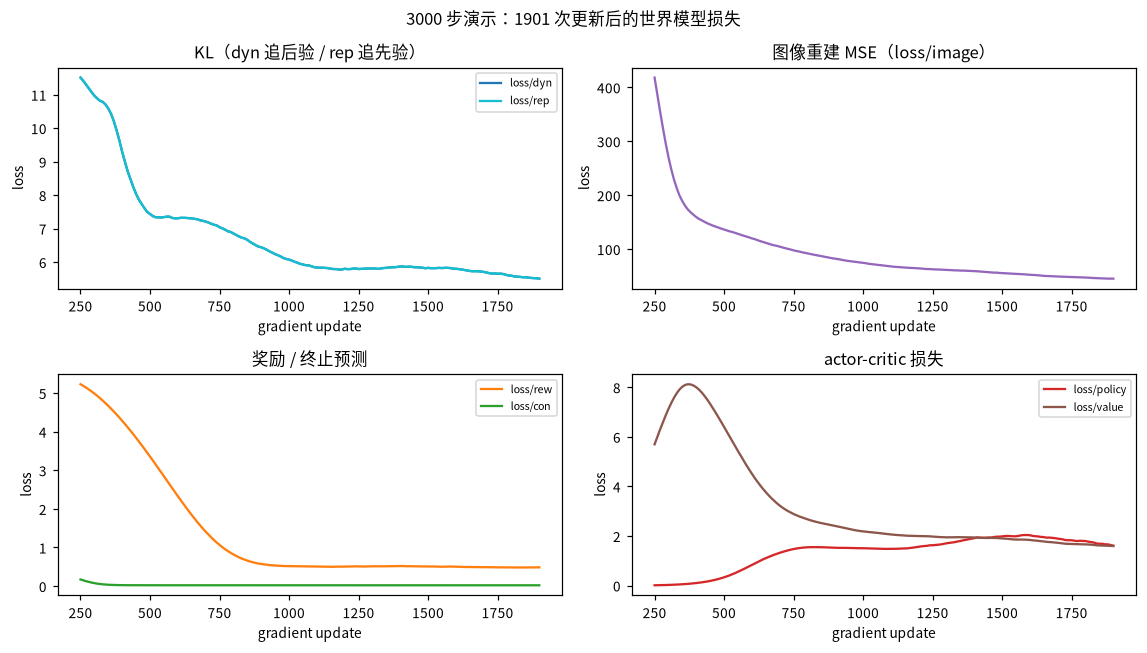

首/末（未平滑）:
  loss/dyn         11.304 ->      5.409
  loss/image      956.460 ->     43.880
  loss/rew          5.541 ->      0.461
  loss/con          0.577 ->      0.021
  loss/repval      11.038 ->      1.923


In [13]:
# 把收集到的指标画成曲线（滑动平均让趋势更清楚）
def series(key, win=25):
    xs, ys = [], []
    for s, m in zip(hist["updates"], hist["mets"]):
        if key in m:
            xs.append(s); ys.append(m[key])
    if len(ys) >= win:
        ys = np.convolve(ys, np.ones(win) / win, mode="valid")
        xs = xs[win - 1:]
    return np.array(xs), np.array(ys)

fig, axs = plt.subplots(2, 2, figsize=(10.5, 6.0))

for key, c in [("loss/dyn", "tab:blue"), ("loss/rep", "tab:cyan")]:
    x, y = series(key); axs[0, 0].plot(x, y, c, label=key)
axs[0, 0].set(title="KL（dyn 追后验 / rep 追先验）", xlabel="gradient update", ylabel="loss")
axs[0, 0].legend(fontsize=7)

x, y = series("loss/image"); axs[0, 1].plot(x, y, "tab:purple")
axs[0, 1].set(title="图像重建 MSE（loss/image）", xlabel="gradient update", ylabel="loss")

for key, c in [("loss/rew", "tab:orange"), ("loss/con", "tab:green")]:
    x, y = series(key); axs[1, 0].plot(x, y, c, label=key)
axs[1, 0].set(title="奖励 / 终止预测", xlabel="gradient update", ylabel="loss")
axs[1, 0].legend(fontsize=7)

for key, c in [("loss/policy", "tab:red"), ("loss/value", "tab:brown")]:
    x, y = series(key); axs[1, 1].plot(x, y, c, label=key)
axs[1, 1].set(title="actor-critic 损失", xlabel="gradient update", ylabel="loss")
axs[1, 1].legend(fontsize=7)

fig.suptitle(f"3000 步演示：{updates} 次更新后的世界模型损失")
plt.tight_layout(); plt.show()

print("首/末（未平滑）:")
for key in ["loss/dyn", "loss/image", "loss/rew", "loss/con", "loss/repval"]:
    vals = [m[key] for m in hist["mets"] if key in m]
    if vals:
        print(f"  {key:12s} {vals[0]:10.3f} -> {vals[-1]:10.3f}")

曲线说明世界模型确实在学：重建误差从几百掉到几十，奖励/终止损失从「瞎猜」掉到很低，
KL 也稳定下来。注意这是**只有 3000 步**的演示；walker 的得分不会明显上涨，
因为 12M 模型在 DMC 视觉上要几十万步才学会走路。

## 8. 开放回路：让世界模型自己预测未来

`Agent.report` 会取一段 batch，把前一半喂给 encoder+RSSM，然后让**世界模型自己在隐空间里
往前走**（动作序列照给，但后一半的观测不给），再解码成图像；它还会把真实帧、重建帧、误差拼成一张 grid。
这是检查世界模型质量最直观的方式。

report 指标: ['openloop/image']
grid: (26, 196, 408, 3) uint8
显示前 8 个时间步 -> (1568, 408, 3)


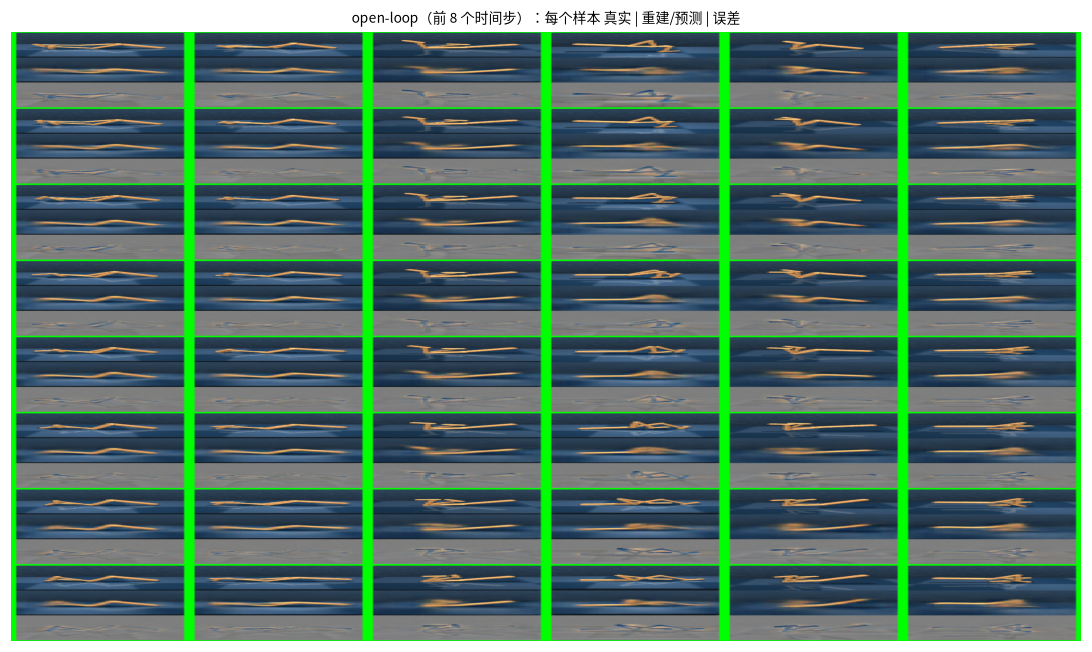

In [14]:
carry_rep = agent.init_report(config.batch_size)
stream_rep = iter(agent.stream(dmain.make_stream(config, replay, "report")))
carry_rep, rep_mets = agent.report(carry_rep, next(stream_rep))

print("report 指标:", [k for k in rep_mets if "openloop" in k])
grid = np.asarray(rep_mets["openloop/image"])
print("grid:", grid.shape, grid.dtype)   # [T, H, B*W, C]，T 行是时间步，列是 batch 样本 × (真实|重建|误差)

Tg, Hg, Wg, Cg = grid.shape
n_show = min(8, Tg)
show = grid[:n_show].reshape(n_show * Hg, Wg, Cg)   # 只显示前 8 个时间步
print("显示前 %d 个时间步 ->" % n_show, show.shape)

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(show, aspect="auto")
ax.axis("off")
ax.set_title("open-loop（前 8 个时间步）：每个样本 真实 | 重建/预测 | 误差", fontsize=9)
plt.tight_layout(); plt.show()

如果世界模型还没训够，预测帧会逐渐模糊、漂移：隐空间里每一步都要从离散分布里采样，
误差会随步数累积。这正是 Dreamer 论文里 Fig. 3 展示的现象：**短期重建很好，长期想象会 bias**——
所以 actor 只在 15 步内做想象，不指望世界模型无限准。

## 9. 对照一次完整的 30 万步训练

本仓库在 2026-11 用同一套代码、同一条命令跑过一次接近完整的 `dmc_walker_walk`
（12M 参数，`size12m`，单张 5090，16 个并行环境；目标 30 万步，实际跑到约 29.9 万步）。
下面直接读它的 `metrics.jsonl` / `scores.jsonl`，看训练到后期曲线长什么样。

run 存在: True /mnt/storage1/syk/dreamer/runs/repro/dmc_vision_walker_12m_s0
scores: 288 条,  metrics: 349 条
最后一条 score: {'step': 288288, 'episode/score': 956.2602997496724}


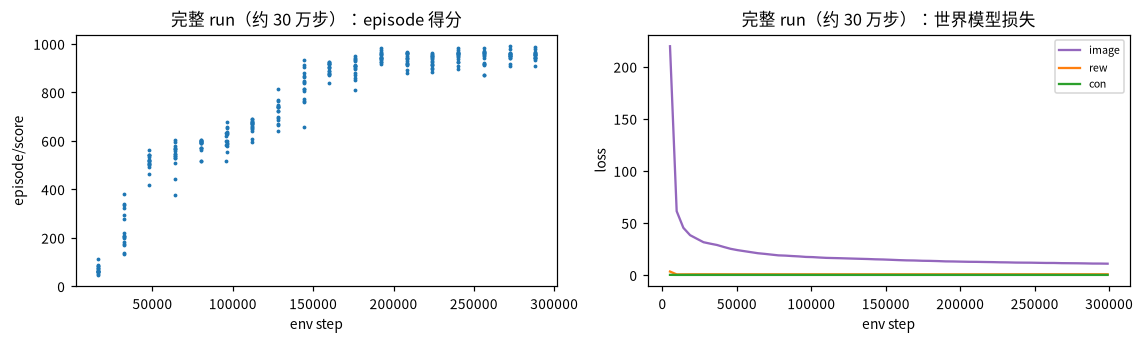

In [15]:
RUN = pathlib.Path("/mnt/storage1/syk/dreamer/runs/repro/dmc_vision_walker_12m_s0")
print("run 存在:", RUN.exists(), RUN)

if RUN.exists():
    scores = [json.loads(l) for l in (RUN / "scores.jsonl").read_text().splitlines() if l.strip()]
    mets = [json.loads(l) for l in (RUN / "metrics.jsonl").read_text().splitlines() if l.strip()]
    print("scores:", len(scores), "条,  metrics:", len(mets), "条")
    print("最后一条 score:", scores[-1] if scores else None)

    fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.2))
    axs[0].plot([s["step"] for s in scores], [s["episode/score"] for s in scores], ".", ms=3)
    axs[0].set(title="完整 run（约 30 万步）：episode 得分", xlabel="env step", ylabel="episode/score")

    for key, c in [("train/loss/image", "tab:purple"), ("train/loss/rew", "tab:orange"),
                   ("train/loss/con", "tab:green")]:
        xs = [m["step"] for m in mets if key in m]
        ys = [m[key] for m in mets if key in m]
        if xs:
            axs[1].plot(xs, ys, c, label=key.replace("train/loss/", ""))
    axs[1].set(title="完整 run（约 30 万步）：世界模型损失", xlabel="env step", ylabel="loss")
    axs[1].legend(fontsize=7)
    plt.tight_layout(); plt.show()
else:
    print("（本机没有这条 run，跳过）")

约 30 万步的 run 里，得分从 ~58 升到 ~956（最高 990），说明世界模型 + 想象训练确实把
walker 教会了走路；损失曲线和 3k 步的形状一致，只是走得更远。这也说明 Dreamer 的训练是
**世界模型先收敛、策略后受益**，两条时间尺度不一样——3k 步的演示只够展示机制，
评价算法要看这种完整量级。

## 10. 与论文/大规模配置的差异、局限和复现命令

| 项目 | 论文 DreamerV3 | 本 notebook |
|-|-|-|
| 模型规模 | 200M（deter 8192 / hidden 1024 / classes 64） | 12M（deter 2048 / hidden 256 / classes 16） |
| 环境步数 | DMC 视觉 1.1M | 3000（演示） |
| `train_ratio` | 256（视觉 DMC） | 1024（演示时更快看到损失变化） |
| 并行环境 | 8（官方 `dmc_vision` 配置） | 1 |
| 优化器 | AGC 0.3 + LaProp，lr 4e-5 | 相同 |
| 结果 | 单卡 A100 数天 | 5090 上约 6 分钟 |

**局限**

- 3000 步不足以让 walker 学会走路，得分曲线不能用来评价算法；
- 单环境、单 seed；官方结果依赖 8 个并行环境带来的数据多样性；
- `size12m` 与论文的 200M 不是同一规模，损失绝对值不可直接比较。

**复现命令**

```bash
conda activate dreamer
export PYTHONPATH=~/labs/Dreamer/repos/dreamerv3
export MUJOCO_GL=egl
python -m nbconvert --to notebook --execute --inplace \
  ~/path/to/notebooks/dreamer/dreamer_training_walkthrough.ipynb
```

**代码地图**（`repos/dreamerv3/`）

| 文件 | 作用 |
|-|-|
| `dreamerv3/agent.py` | 7 个模块、世界模型 + 想象损失、优化器超参 |
| `dreamerv3/rssm.py` | RSSM 动力学、先验/后验、KL、`imagine` |
| `embodied/jax/nets.py`, `heads.py`, `outs.py` | CNN/MLP、two-hot、bounded normal、symlog |
| `embodied/jax/opt.py` | AGC 裁剪、LaProp、优化器封装 |
| `embodied/core/replay.py` | 回放存储 / 连续采样 |
| `embodied/run/train.py` | 真实训练循环（本 notebook 第 7 节是它的等价简化） |
| `dreamerv3/configs.yaml` | 所有超参和规模档位 |